# 18 — Commitment-region probe

Pivot from nb 17. The attention sweep didn't show a sparse "look-back" head set. New hypothesis (**commitment region**): at the *first few tokens* of each labeled code-span there is a strong, linearly-decodable "I am committing to step k" signal in the residual stream. In the middle of the span the signal just persists, and need not be re-asserted.

Setup mirrors nb 16 (Schut-style hinge loss in residual space, layer sweep, shuffled-label control), but the contrast is **within-sample, within-step**:

- **Positive (commitment)**: first $N$ tokens of each step's `gen_token_range`.
- **Negative**:
  - *mid-span tokens of the same step* — controls for sample/function/prompt.
  - *non-span-start line-starts within the step* (lines 2..end of the step's block) — controls for the "newline → indent" syntactic confound. Without this, a probe could just be detecting line boundaries.

We run $N=1$ and $N=3$ in parallel and sweep layers in steps of 4.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import json
import random
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils, env_utils

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "3,4,7"

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, highlight=False)

def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)

logging_utils.configure(level=logging.INFO)

In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")

2026-06-02 15:49:04 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-06-02 15:49:04 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-02 15:49:04 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-06-02 15:49:04 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-02 15:49:04 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-06-02 15:49:04 httpx INFO     HTT

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-06-02 15:49:27 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-02 15:49:27 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-06-02 15:49:27 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40


## 1. Load labeled generations

We reuse the oracle labels produced by `scripts/clock/build_multistep_clock_data.py`. Each `LabeledGeneration` carries the full prompt, the generation, and one `StepLabel` per step with `gen_token_range` and `gen_line_range` already resolved against the tokenization of `full_prompt + generation` (add_special_tokens=False).

In [4]:
from src.goals.multistep_data import MultiStepDataset
from src.goals.multistep_label import LabeledGeneration

DATA_ROOT = Path(env_utils.DEFAULT_RESULTS_DIR) / "multistep_clock" / mt.name.split("/")[-1]
DATASET_PATH = Path(env_utils.DEFAULT_DATA_DIR) / "multistep" / "seed.json"

ds = MultiStepDataset.load_dataset(str(DATASET_PATH))
name_to_sample = {s.name: s for s in ds.samples}

MODALITIES = ["modular", "monolithic"]
records = []  # one per (sample, modularity) — only those with valid labels.json
for modularity in MODALITIES:
    mod_dir = DATA_ROOT / modularity
    if not mod_dir.exists():
        print(f"  [warn] missing dir: {mod_dir}")
        continue
    for sample_dir in sorted(mod_dir.iterdir()):
        labels_path = sample_dir / "labels.json"
        if not labels_path.exists():
            continue
        with open(labels_path) as f:
            lab = LabeledGeneration.from_dict(json.load(f))
        if lab.sample_name not in name_to_sample:
            continue
        records.append({
            "sample_name": lab.sample_name,
            "modularity": modularity,
            "labeled": lab,
            "sample": name_to_sample[lab.sample_name],
        })

print(f"loaded {len(records)} labeled (sample, modularity) records")
print(f"  modular:    {sum(r['modularity'] == 'modular'    for r in records)}")
print(f"  monolithic: {sum(r['modularity'] == 'monolithic' for r in records)}")

2026-06-02 15:49:27 src.goals.multistep_data INFO     loaded MultiStepDataset: 106 samples from /disk/u/arnab/Codes/Projects/goals/data/multistep/seed.json
loaded 212 labeled (sample, modularity) records
  modular:    106
  monolithic: 106


## 2. Build positive / negative position sets

For each record we re-tokenize `combined = full_prompt + generation` (with offsets) and, per step, partition the tokens in `gen_token_range` into three roles:

- `span_start` — first $N$ tokens.
- `nonstart_linestart` — first token of each subsequent line in the step's block.
- `mid_span` — the remainder.

The contrast for the probe is `span_start` vs `mid_span ∪ nonstart_linestart`. We keep them tagged so we can analyze the two negative subtypes separately later. For monolithic generations we **skip the last step's labels** (its `gen_token_range` bleeds across the others — see nb 17 hypothesis discussion).

In [5]:
from dataclasses import dataclass

@dataclass
class TokenRow:
    sample_name: str
    modularity: str
    step_idx: int
    role: str             # 'span_start' | 'nonstart_linestart' | 'mid_span'
    token_pos: int        # absolute token index in `combined`
    first_token_str: str  # decoded token text — for confound-holdout slicing


def _line_starts_in_range(
    full_prompt: str, generation: str, sl: int, el: int, offsets: list[tuple[int, int]]
) -> list[int]:
    """Token indices into `combined` that are the first non-empty token of each
    line in the 1-based inclusive line range [sl, el] of `generation`."""
    char_offset = len(full_prompt)
    gen_lines = generation.splitlines(keepends=True)
    sl = max(1, sl); el = min(el, len(gen_lines))
    line_starts: list[int] = []
    cum = 0
    for li, line in enumerate(gen_lines, start=1):
        line_start_char = char_offset + cum
        cum += len(line)
        if li < sl or li > el:
            continue
        # first token whose start offset lies at or beyond `line_start_char`
        tok = next(
            (j for j, (a, b) in enumerate(offsets) if a >= line_start_char and b > a),
            None,
        )
        if tok is not None:
            line_starts.append(tok)
    return line_starts


def extract_token_rows(record: dict, mt, N: int) -> list[TokenRow]:
    """Partition each step's gen_token_range into role-tagged token positions.

    For monolithic: skip the last step (its block usually subsumes all prior steps).
    """
    lab = record["labeled"]
    combined = lab.full_prompt + lab.generation
    enc = mt.tokenizer(combined, return_offsets_mapping=True, add_special_tokens=False)
    offsets = [tuple(p) for p in enc["offset_mapping"]]
    input_ids = enc["input_ids"]

    is_monolithic = record["modularity"] == "monolithic"
    n_steps = len(lab.labels)
    rows: list[TokenRow] = []
    for i, step in enumerate(lab.labels):
        if is_monolithic and i == n_steps - 1:
            continue
        if step.gen_token_range is None or step.gen_line_range is None:
            continue
        t_start, t_end = step.gen_token_range  # end exclusive
        if t_end - t_start < 2:
            continue

        span_start_idx = list(range(t_start, min(t_start + N, t_end)))
        sl, el = step.gen_line_range
        line_starts = _line_starts_in_range(
            lab.full_prompt, lab.generation, sl, el, offsets
        )
        # Non-start line-starts: line-starts of lines after the first one in the step.
        first_line_starts = set(span_start_idx)
        nonstart_linestarts = [
            t for t in line_starts
            if t_start <= t < t_end and t not in first_line_starts
        ]
        # Mid-span: everything inside the range that isn't span_start or linestart.
        excluded = set(span_start_idx) | set(nonstart_linestarts)
        mid_span = [t for t in range(t_start, t_end) if t not in excluded]

        for t in span_start_idx:
            rows.append(TokenRow(
                sample_name=record["sample_name"],
                modularity=record["modularity"],
                step_idx=i, role="span_start", token_pos=t,
                first_token_str=mt.tokenizer.decode([input_ids[t]]),
            ))
        for t in nonstart_linestarts:
            rows.append(TokenRow(
                sample_name=record["sample_name"],
                modularity=record["modularity"],
                step_idx=i, role="nonstart_linestart", token_pos=t,
                first_token_str=mt.tokenizer.decode([input_ids[t]]),
            ))
        for t in mid_span:
            rows.append(TokenRow(
                sample_name=record["sample_name"],
                modularity=record["modularity"],
                step_idx=i, role="mid_span", token_pos=t,
                first_token_str=mt.tokenizer.decode([input_ids[t]]),
            ))
    return rows


# Build the two variants in parallel.
N_VALUES = [1, 3]
rows_by_N: dict[int, list[TokenRow]] = {}
for N in N_VALUES:
    all_rows = []
    for r in records:
        all_rows.extend(extract_token_rows(r, mt, N=N))
    rows_by_N[N] = all_rows
    role_counts = pd.Series([r.role for r in all_rows]).value_counts().to_dict()
    print(f"N={N}: {len(all_rows)} rows  {role_counts}")

N=1: 36610 rows  {'mid_span': 32626, 'nonstart_linestart': 3241, 'span_start': 743}
N=3: 36610 rows  {'mid_span': 31140, 'nonstart_linestart': 3241, 'span_start': 2229}


## 3. Extract hidden states

One forward pass per (sample, modularity); fetch residual-stream activations at the swept layers and the union of positions across both $N$ variants. About 212 forward passes total.

In [6]:
from src.functional import get_hs
from src.tokens import prepare_input

LAYERS_SWEEP = list(range(0, mt.n_layer, 4))
if (mt.n_layer - 1) not in LAYERS_SWEEP:
    LAYERS_SWEEP.append(mt.n_layer - 1)
LAYERS_SWEEP = sorted(LAYERS_SWEEP)
print(f"sweeping {len(LAYERS_SWEEP)} layers: {LAYERS_SWEEP}")

# All positions we need per record = union of token_pos across both N values.
key = lambda r: (r.sample_name, r.modularity)
positions_per_record: dict[tuple[str, str], set[int]] = {}
for N in N_VALUES:
    for r in rows_by_N[N]:
        positions_per_record.setdefault(key(r), set()).add(r.token_pos)

# hs_cache[(sample, modularity)] = dict (layer_idx -> dict pos -> tensor(d,))
hs_cache: dict[tuple[str, str], dict[int, dict[int, torch.Tensor]]] = {}

@torch.no_grad()
def cache_one(record: dict):
    k = (record["sample_name"], record["modularity"])
    if k in hs_cache:
        return
    positions = sorted(positions_per_record.get(k, set()))
    if not positions:
        return
    combined = record["labeled"].full_prompt + record["labeled"].generation
    tokenized = prepare_input(prompts=combined, tokenizer=mt)
    layer_names = [mt.layer_names[L] for L in LAYERS_SWEEP]
    locations = [(ly, t) for ly in layer_names for t in positions]
    hs_dict = get_hs(mt=mt, input=tokenized, locations=locations, return_dict=True)
    out: dict[int, dict[int, torch.Tensor]] = {}
    for L, ly in zip(LAYERS_SWEEP, layer_names):
        out[L] = {
            t: hs_dict[(ly, t)].detach().to("cpu", dtype=torch.float16)
            for t in positions
        }
    hs_cache[k] = out

for r in tqdm(records, desc="hs"):
    try:
        cache_one(r)
    except Exception as e:
        print(f"  [warn] {r['sample_name']}/{r['modularity']}: {e}")

print(f"cached HS for {len(hs_cache)} records")

sweeping 17 layers: [0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60, 63]


hs:   0%|          | 0/212 [00:00<?, ?it/s]

cached HS for 212 records


## 4. Train/test split + constraint sampling

Hold out **whole samples** (not individual tokens) to prevent leakage. A constraint is a pair $(z^+, z^-)$ where $z^+$ is a `span_start` row and $z^-$ is a same-sample, same-modularity `mid_span` or `nonstart_linestart` row. Within-record matching makes the optimizer ignore prompt/function identity.

In [7]:
SEED = 0
TEST_FRAC = 0.2
TRAIN_LIMIT = 10_000
rng = random.Random(SEED)

all_sample_names = sorted({r["sample_name"] for r in records})
shuffled = list(all_sample_names); rng.shuffle(shuffled)
n_test = max(1, int(len(shuffled) * TEST_FRAC))
test_names = set(shuffled[:n_test])
train_names = set(shuffled[n_test:])
print(f"split: train={len(train_names)} test={len(test_names)} samples")

def split_rows(rows: list[TokenRow]):
    train = [r for r in rows if r.sample_name in train_names]
    test  = [r for r in rows if r.sample_name in test_names]
    return train, test

def index_by_record(rows: list[TokenRow]):
    """Group rows by (sample, modularity) → {role: [rows]}."""
    by_rec: dict[tuple[str, str], dict[str, list[TokenRow]]] = {}
    for r in rows:
        d = by_rec.setdefault((r.sample_name, r.modularity), {})
        d.setdefault(r.role, []).append(r)
    return by_rec


def sample_constraints(rows: list[TokenRow], n: int, rng_local: random.Random) -> list[tuple[TokenRow, TokenRow]]:
    """Within-record pairs of (span_start, mid_span ∪ nonstart_linestart)."""
    by_rec = index_by_record(rows)
    eligible = [
        k for k, d in by_rec.items()
        if d.get("span_start") and (d.get("mid_span") or d.get("nonstart_linestart"))
    ]
    if not eligible:
        return []
    pairs = []
    while len(pairs) < n:
        k = rng_local.choice(eligible)
        d = by_rec[k]
        pos_row = rng_local.choice(d["span_start"])
        negs = (d.get("mid_span", []) + d.get("nonstart_linestart", []))
        neg_row = rng_local.choice(negs)
        pairs.append((pos_row, neg_row))
    return pairs


rows_train_by_N, rows_test_by_N, quads_train_by_N = {}, {}, {}
for N in N_VALUES:
    tr, te = split_rows(rows_by_N[N])
    rows_train_by_N[N] = tr
    rows_test_by_N[N]  = te
    quads_train_by_N[N] = sample_constraints(tr, TRAIN_LIMIT, rng)
    print(f"N={N}: train rows={len(tr)} test rows={len(te)} quads={len(quads_train_by_N[N])}")

split: train=85 test=21 samples
N=1: train rows=29416 test rows=7194 quads=10000
N=3: train rows=29416 test rows=7194 quads=10000


## 5. Optimize direction

Schut-style hinge on unit-normalized residual-stream activations. Warm start from $\bar{z}^+ - \bar{z}^-$; project to the sphere after each step.

In [8]:
def hs_at(row: TokenRow, layer_idx: int, normalize: bool = True) -> torch.Tensor:
    k = (row.sample_name, row.modularity)
    h = hs_cache[k][layer_idx][row.token_pos].to(torch.float32)
    if normalize:
        h = h / (h.norm() + 1e-9)
    return h


def stack_rows(rows: list[TokenRow], layer_idx: int, normalize: bool = True) -> torch.Tensor:
    return torch.stack([hs_at(r, layer_idx, normalize) for r in rows], dim=0)


def optimize_direction(
    pos_rows: list[TokenRow],
    neg_rows: list[TokenRow],
    pair_idx: list[tuple[int, int]],
    layer_idx: int,
    *,
    margin: float = 0.1,
    lr: float = 1e-2,
    n_steps: int = 300,
    batch_size: int = 1024,
    seed: int = 0,
    device: str = "cuda",
    random_init: bool = False,
    verbose: bool = False,
):
    Zp = torch.stack([hs_at(pos_rows[i], layer_idx) for i, _ in pair_idx]).to(device)
    Zn = torch.stack([hs_at(neg_rows[j], layer_idx) for _, j in pair_idx]).to(device)
    diffs = (Zp - Zn).contiguous()
    d = diffs.shape[-1]; N = diffs.shape[0]

    if random_init:
        g = torch.Generator(device=device).manual_seed(seed)
        init = torch.randn(d, generator=g, device=device)
    else:
        init = Zp.mean(dim=0) - Zn.mean(dim=0)
    v = (init / (init.norm() + 1e-9)).clone().detach().requires_grad_(True)
    opt = torch.optim.Adam([v], lr=lr)

    hist = {"loss": [], "sat": []}
    for step in range(n_steps):
        idx = torch.randint(0, N, (batch_size,), device=device)
        b = diffs[idx]
        v_unit = v / (v.norm() + 1e-9)
        margins_b = (b * v_unit).sum(dim=-1)
        loss = torch.clamp(margin - margins_b, min=0).mean()
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        if step % max(1, n_steps // 20) == 0 or step == n_steps - 1:
            with torch.no_grad():
                v_u = v / (v.norm() + 1e-9)
                sat = ((diffs * v_u).sum(dim=-1) > 0).float().mean().item()
            hist["loss"].append(loss.item()); hist["sat"].append(sat)
            if verbose:
                print(f"  step {step:4d}  loss={loss.item():.4f}  sat={sat:.3f}")
    return (v / (v.norm() + 1e-9)).detach().cpu(), hist


def mean_diff_direction(pos_rows: list[TokenRow], neg_rows: list[TokenRow], layer_idx: int) -> torch.Tensor:
    P = stack_rows(pos_rows, layer_idx)
    Nn = stack_rows(neg_rows, layer_idx)
    v = P.mean(dim=0) - Nn.mean(dim=0)
    return v / (v.norm() + 1e-9)

## 6. Layer sweep — $N=1$ vs $N=3$

For each swept layer, fit a hinge-loss direction on the training quads and score constraint-satisfaction on a held-out batch of test quads.

In [9]:
TEST_QUADS_LIMIT = 4000
MARGIN = 0.1
LR = 1e-2
N_STEPS = 300

def constraint_sat(v: torch.Tensor, pairs: list[tuple[TokenRow, TokenRow]], layer_idx: int) -> float:
    if not pairs:
        return float("nan")
    diffs = torch.stack([hs_at(p, layer_idx) - hs_at(n, layer_idx) for p, n in pairs])
    return ((diffs * v).sum(dim=-1) > 0).float().mean().item()

sweep_results: dict[int, list[dict]] = {}
for N in N_VALUES:
    tr_rows = rows_train_by_N[N]; te_rows = rows_test_by_N[N]
    quads = quads_train_by_N[N]
    # For the optimizer we need indexable lists of positives/negatives.
    pos_rows_tr = [p for p, _ in quads]
    neg_rows_tr = [n for _, n in quads]
    pair_idx = [(i, i) for i in range(len(quads))]

    test_pairs = sample_constraints(te_rows, TEST_QUADS_LIMIT, random.Random(1))
    rows_out = []
    for L in LAYERS_SWEEP:
        v_opt, _ = optimize_direction(
            pos_rows_tr, neg_rows_tr, pair_idx, layer_idx=L,
            margin=MARGIN, lr=LR, n_steps=N_STEPS, verbose=False,
        )
        v_md = mean_diff_direction(pos_rows_tr, neg_rows_tr, L)
        sat_tr_opt = constraint_sat(v_opt, quads, L)
        sat_te_opt = constraint_sat(v_opt, test_pairs, L)
        sat_te_md  = constraint_sat(v_md,  test_pairs, L)
        rows_out.append({
            "layer": L, "sat_train_opt": sat_tr_opt,
            "sat_test_opt": sat_te_opt, "sat_test_md": sat_te_md,
            "v_opt": v_opt, "v_md": v_md,
        })
        print(f"N={N} layer={L:3d}  sat_te_opt={sat_te_opt:.3f}  sat_te_md={sat_te_md:.3f}")
    sweep_results[N] = rows_out

N=1 layer=  0  sat_te_opt=0.995  sat_te_md=0.990
N=1 layer=  4  sat_te_opt=0.996  sat_te_md=0.992
N=1 layer=  8  sat_te_opt=0.995  sat_te_md=0.992
N=1 layer= 12  sat_te_opt=0.996  sat_te_md=0.992
N=1 layer= 16  sat_te_opt=0.995  sat_te_md=0.993
N=1 layer= 20  sat_te_opt=0.996  sat_te_md=0.994
N=1 layer= 24  sat_te_opt=0.996  sat_te_md=0.993
N=1 layer= 28  sat_te_opt=0.996  sat_te_md=0.992
N=1 layer= 32  sat_te_opt=0.996  sat_te_md=0.993
N=1 layer= 36  sat_te_opt=0.996  sat_te_md=0.993
N=1 layer= 40  sat_te_opt=0.996  sat_te_md=0.992
N=1 layer= 44  sat_te_opt=0.996  sat_te_md=0.993
N=1 layer= 48  sat_te_opt=0.996  sat_te_md=0.990
N=1 layer= 52  sat_te_opt=0.996  sat_te_md=0.990
N=1 layer= 56  sat_te_opt=0.996  sat_te_md=0.992
N=1 layer= 60  sat_te_opt=0.996  sat_te_md=0.991
N=1 layer= 63  sat_te_opt=0.993  sat_te_md=0.986
N=3 layer=  0  sat_te_opt=0.917  sat_te_md=0.841
N=3 layer=  4  sat_te_opt=0.977  sat_te_md=0.956
N=3 layer=  8  sat_te_opt=0.976  sat_te_md=0.959
N=3 layer= 12  sat_t

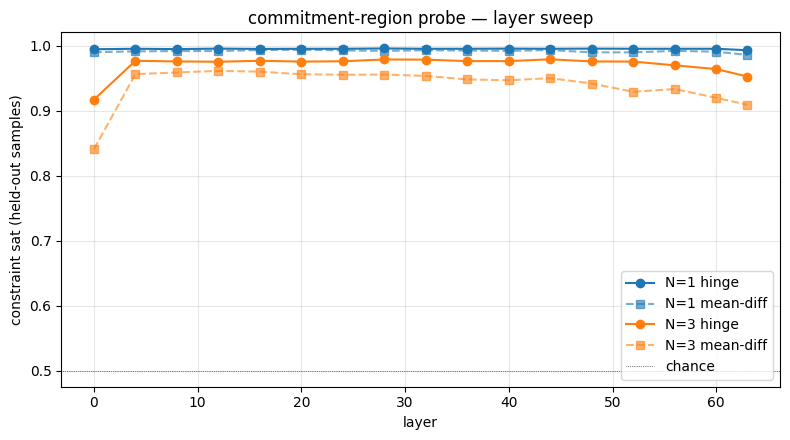

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for N, color in zip(N_VALUES, ["tab:blue", "tab:orange"]):
    df = pd.DataFrame([{k: r[k] for k in r if not k.startswith("v_")} for r in sweep_results[N]])
    ax.plot(df["layer"], df["sat_test_opt"], "o-", color=color, label=f"N={N} hinge")
    ax.plot(df["layer"], df["sat_test_md"],  "s--", color=color, alpha=0.6, label=f"N={N} mean-diff")
ax.axhline(0.5, color="k", lw=0.5, ls=":", label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("constraint sat (held-out samples)")
ax.set_title("commitment-region probe — layer sweep")
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Confound checks

1. **Token-identity hold-out**: refit with all `span_start` rows whose first token is `def`, `for`, `if`, `while`, `return` *excluded*. If accuracy collapses, the probe was reading the lexicon.
2. **Shuffled-label control**: random positive/negative assignment within each record. Should sit at chance.

In [ ]:
SYNTACTIC_BLACKLIST = {"def", "for", "if", "while", "return", "with", "try", "class"}

def first_tok_clean(s: str) -> str:
    return s.strip().split()[0] if s.strip() else ""

best_layer = {
    N: max(sweep_results[N], key=lambda r: r["sat_test_opt"])["layer"]
    for N in N_VALUES
}
print("best layers per N:", best_layer)

for N in N_VALUES:
    L = best_layer[N]
    tr_rows = [r for r in rows_train_by_N[N] if not (r.role == "span_start" and first_tok_clean(r.first_token_str) in SYNTACTIC_BLACKLIST)]
    te_rows = [r for r in rows_test_by_N[N]  if not (r.role == "span_start" and first_tok_clean(r.first_token_str) in SYNTACTIC_BLACKLIST)]
    rng_c = random.Random(SEED + 17)
    tr_pairs = sample_constraints(tr_rows, TRAIN_LIMIT, rng_c)
    te_pairs = sample_constraints(te_rows, TEST_QUADS_LIMIT, rng_c)
    pos_rows_tr = [p for p, _ in tr_pairs]
    neg_rows_tr = [n for _, n in tr_pairs]
    v_h, _ = optimize_direction(
        pos_rows_tr, neg_rows_tr, [(i, i) for i in range(len(tr_pairs))],
        layer_idx=L, margin=MARGIN, lr=LR, n_steps=N_STEPS,
    )
    sat_te = constraint_sat(v_h, te_pairs, L)
    print(f"N={N} layer={L} blacklist-held-out sat_te={sat_te:.3f}")

best layers per N: {1: 28, 3: 44}
N=1 layer=28 blacklist-held-out sat_te=0.995
N=3 layer=44 blacklist-held-out sat_te=0.988


In [12]:
N_SHUFFLE_SEEDS = 5
for N in N_VALUES:
    L = best_layer[N]
    sats = []
    for s in range(N_SHUFFLE_SEEDS):
        rng_s = random.Random(200 + s)
        # shuffle role labels within each (sample, modularity)
        rows = rows_train_by_N[N]
        by_rec = index_by_record(rows)
        fake_rows = []
        for k, d in by_rec.items():
            pool = sum(d.values(), [])
            n_pos = len(d.get("span_start", []))
            rng_s.shuffle(pool)
            for i, r in enumerate(pool):
                fake_role = "span_start" if i < n_pos else "mid_span"
                fake_rows.append(TokenRow(
                    r.sample_name, r.modularity, r.step_idx,
                    fake_role, r.token_pos, r.first_token_str,
                ))
        fake_pairs = sample_constraints(fake_rows, TRAIN_LIMIT, rng_s)
        if not fake_pairs:
            continue
        v_f, _ = optimize_direction(
            [p for p, _ in fake_pairs], [n for _, n in fake_pairs],
            [(i, i) for i in range(len(fake_pairs))],
            layer_idx=L, margin=MARGIN, lr=LR, n_steps=N_STEPS, random_init=True, seed=s,
        )
        te_pairs = sample_constraints(rows_test_by_N[N], TEST_QUADS_LIMIT, rng_s)
        sat = constraint_sat(v_f, te_pairs, L)
        sats.append(sat)
    if sats:
        print(f"N={N} layer={L} shuffled-control sat_te: mean={np.mean(sats):.3f}  std={np.std(sats):.3f}  ({sats})")

N=1 layer=28 shuffled-control sat_te: mean=0.433  std=0.174  ([0.4817500114440918, 0.5142499804496765, 0.6700000166893005, 0.15399999916553497, 0.3434999883174896])
N=3 layer=44 shuffled-control sat_te: mean=0.497  std=0.106  ([0.42774999141693115, 0.42774999141693115, 0.6884999871253967, 0.40450000762939453, 0.5375000238418579])


## 9. Where does the probe fire on a real generation?

Pick a held-out (sample, modularity), do one forward pass to get residual states at **every** token position in the generation range, project onto the trained $v_\text{opt}$ at the best layer, and render with `circuitsvis.colored_tokens`. Ground-truth `span_start` positions are wrapped in `[[ ]]` so we can compare the probe's hot regions against the oracle labels.

Mirrors the visualization pattern from `08_clock.ipynb` cell `1e23d19b` (colored tokens by cosine to probe weight) — but here scores come from $v_\text{opt} \cdot \hat z$ on unit-normalized residuals, matching the training-time objective.

In [53]:
from src.tokens import prepare_input
from rich.table import Table
from rich.text import Text

held_out_records = [r for r in records if r["sample_name"] in test_names]
# demo = held_out_records[12]
demo = [d for d in held_out_records if d["modularity"] == "monolithic"][5]

rich_print(f"[white]{demo['labeled'].full_prompt}[/white][sea_green3]{demo['labeled'].generation}[/sea_green3]")

full_prompt = demo['labeled'].full_prompt + demo['labeled'].generation
input_ids = prepare_input(prompts=full_prompt, tokenizer=mt).input_ids

table = Table(title=f"step labeling — {demo['labeled'].sample_name}", show_lines=True)
table.add_column("k", justify="right", style="bright_white")
table.add_column("step (truncated)", overflow="fold", max_width=46)
table.add_column("prompt tok", justify="center", style="cyan")
table.add_column("gen line", justify="center", style="yellow")
table.add_column("gen tok", justify="center", style="green")
table.add_column("gen code (truncated)", overflow="fold", max_width=250)

for lbl in demo['labeled'].labels:
    step_short = lbl.step_text if len(lbl.step_text) < 80 else lbl.step_text[:77] + "…"
    p_str = f"{lbl.prompt_token_range[0]}–{lbl.prompt_token_range[1]}" if lbl.prompt_token_range else "—"
    line_str = f"{lbl.gen_line_range[0]}–{lbl.gen_line_range[1]}" if lbl.gen_line_range else "—"
    tok_str = f"{lbl.gen_token_range[0]}–{lbl.gen_token_range[1]}" if lbl.gen_token_range else "—"
    code_short = lbl.gen_code.replace("\n", "↵\n").strip()
    if len(code_short) > 200:
        code_short = code_short[:197] + "…"
    table.add_row(str(lbl.step_idx), step_short, p_str, line_str, tok_str, code_short)

console.print(table)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a python code that does the following:

1. Parse the CSV path, the group-by column, and the value column from arguments.
2. Load the CSV into row dictionaries.
3. Group the rows by the group column and accumulate the value column inside each group.
4. Print each group's key, count, sum, and mean, sorted by descending sum.

Put all the logic inside a single function `main()` (taking no arguments) — do not define any helper functions. If 
a step requires reading from a file path, the command line, or standard input, do that inside `main()` as well.
Do not add any comments or docstrings. Only provide the code.<|im_end|>
<|im_start|>assistant
<code>
def main():
    import sys
    import csv
    from collections import defaultdict

    args = sys.argv[1:]
    csv_path, group_by, value_col = args

    with open(csv_path, mode='r', newline='') as file:
        reader = csv.DictReader(file)
        data = list(reader)

    grouped_data = defaultdict(lambda: {'count': 0, 'sum': 0})
    for row in data:
        key = row
        value = float(row)
        grouped_data['count'] += 1
        grouped_data['sum'] += value

    sorted_groups = sorted(grouped_data.items(), key=lambda x: x[1]['sum'], reverse=True)

    for key, stats in sorted_groups:
        mean = stats['sum'] / stats['count']
        print(f"{key}, {stats['count']}, {stats['sum']}, {mean}")
</code>

                                          step labeling — csv_groupby_cli                                          
┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ k ┃ step (truncated)                    ┃ prompt tok ┃ gen line ┃ gen tok ┃ gen code (truncated)                ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 0 │ Parse the CSV path, the group-by    │   55–72    │   5–6    │ 209–228 │ args = sys.argv[1:]↵                │
│   │ column, and the value column from   │            │          │         │     csv_path, group_by, value_col = │
│   │ arguments.                          │            │          │         │ args↵                               │
├───┼─────────────────────────────────────┼────────────┼──────────┼─────────┼─────────────────────────────────────┤
│ 1 │ Load the CSV into row dictionaries. │   74–81    │   8–10   │ 229–257 │ with open(csv_path, mode='r',       │
│   │                                     │            │          │         │ newline='') as file:↵               │
│   │                                     │            │          │         │         reader =                    │
│   │                                     │            │          │         │ csv.DictReader(file)↵               │
│   │                                     │            │          │         │         data = list(reader)↵        │
├───┼─────────────────────────────────────┼────────────┼──────────┼─────────┼─────────────────────────────────────┤
│ 2 │ Group the rows by the group column  │   83–99    │  12–17   │ 258–318 │ grouped_data = defaultdict(lambda:  │
│   │ and accumulate the value column     │            │          │         │ {'count': 0, 'sum': 0})↵            │
│   │ inside eac…                         │            │          │         │     for row in data:↵               │
│   │                                     │            │          │         │         key = row↵                  │
│   │                                     │            │          │         │         value = float(row)↵         │
│   │                                     │            │          │         │         grouped_data['count'] += 1↵ │
│   │                                     │            │          │         │       …                             │
├───┼─────────────────────────────────────┼────────────┼──────────┼─────────┼─────────────────────────────────────┤
│ 3 │ Print each group's key, count, sum, │  101–119   │  19–23   │ 319–384 │ sorted_groups =                     │
│   │ and mean, sorted by descending sum. │            │          │         │ sorted(grouped_data.items(),        │
│   │                                     │            │          │         │ key=lambda x: x[1]['sum'],          │
│   │                                     │            │          │         │ reverse=True)↵                      │
│   │                                     │            │          │         │ ↵                                   │
│   │                                     │            │          │         │     for key, stats in               │
│   │                                     │            │          │         │ sorted_groups:↵                     │
│   │                                     │            │          │         │         mean = stats['sum'] /       │
│   │                                     │            │          │         │ stats['count']↵                     │
│   │                                     │            │          │         │         print(f"{key}, {…           │
└───┴─────────────────────────────────────┴────────────┴──────────┴─────────┴─────────────────────────────────────┘

In [72]:
from circuitsvis.tokens import colored_tokens
from IPython.display import display
from src.attention import _safe_token
from src.tokens import find_token_range

_GLYPH_NL = "\n↵"
_GLYPH_TAB = "⇥"
_GLYPH_DOT = "·"


def _vis_tok(s: str) -> str:
    """Make whitespace tokens visible in both inline display and tooltip.

    circuitsvis renders the same string in both places, so we substitute
    visible glyphs for non-printable whitespace. Mirrors the goalscope
    `render_patchscope_html` fix (src/goals/goalscope.py:466).
    """
    s = s.replace("<", "\uff1c").replace(">", "\uff1e")  # HTML-safe (from _safe_token)
    s = s.replace("\n", _GLYPH_NL).replace("\r", _GLYPH_NL).replace("\t", _GLYPH_TAB)
    if s.strip() == "" and len(s) > 0:
        s = _GLYPH_DOT * len(s)
    return s


def get_v_for(N: int, layer: int) -> torch.Tensor:
    row = next(r for r in sweep_results[N] if r["layer"] == layer)
    return row["v_opt"]


@torch.no_grad()
def render_probe_activity_for_record(
    record, N: int, layer: int, start_from: str | None = None
):
    """Project v_opt onto every token of `full_prompt + generation` and render."""
    lab = record["labeled"]
    combined = lab.full_prompt + lab.generation
    tokenized = prepare_input(
        prompts=combined, tokenizer=mt, return_offsets_mapping=True
    )
    offsets = tokenized.pop("offset_mapping")[0]

    input_ids = tokenized.input_ids[0]

    start_pos = 0
    if start_from is not None:
        start_pos, _ = find_token_range(
            string=combined,
            substring=start_from,
            offset_mapping=offsets,
        )
    positions = list(range(start_pos, len(input_ids)))

    tokenized = prepare_input(prompts=combined, tokenizer=mt)
    ly = mt.layer_names[layer]
    hs_dict = get_hs(
        mt=mt,
        input=tokenized,
        locations=[(ly, t) for t in positions],
        return_dict=True,
    )

    v = get_v_for(N, layer).to(torch.float32)
    scores = []
    for t in positions:
        h = hs_dict[(ly, t)].detach().to("cpu", dtype=torch.float32)
        h = h / (h.norm() + 1e-9)
        scores.append((h * v).sum().item())

    tokens = [_vis_tok(mt.tokenizer.decode([tid])) for tid in input_ids]
    span_starts = {
        s.gen_token_range[0] for s in lab.labels if s.gen_token_range is not None
    }
    marked = [
        f"[[{tok}]]" if i + start_pos in span_starts else tok
        for i, tok in enumerate(tokens[start_pos:])
    ]

    print(
        f"sample={record['sample_name']}  modularity={record['modularity']}  N={N}  layer={layer}"
    )
    print(f"score range: [{min(scores):.3f}, {max(scores):.3f}]")
    print("=" * 80)
    display(
        colored_tokens(
            marked,
            scores,
            positive_color="seagreen",
            negative_color="firebrick",
        )
    )


@torch.no_grad()
def render_probe_activity_for_text(text: str, N: int, layer: int):
    """Project v_opt onto every token of `full_prompt + generation` and render."""

    input_ids = mt.tokenizer(text, add_special_tokens=False)["input_ids"]
    positions = list(range(len(input_ids)))

    tokenized = prepare_input(prompts=text, tokenizer=mt)
    ly = mt.layer_names[layer]
    hs_dict = get_hs(
        mt=mt,
        input=tokenized,
        locations=[(ly, t) for t in positions],
        return_dict=True,
    )

    v = get_v_for(N, layer).to(torch.float32)
    scores = []
    for t in positions:
        h = hs_dict[(ly, t)].detach().to("cpu", dtype=torch.float32)
        h = h / (h.norm() + 1e-9)
        scores.append((h * v).sum().item())

    tokens = [_vis_tok(mt.tokenizer.decode([tid])) for tid in input_ids]

    print(f"score range: [{min(scores):.3f}, {max(scores):.3f}]")
    print("=" * 80)
    display(
        colored_tokens(
            tokens,
            scores,
            positive_color="seagreen",
            negative_color="firebrick",
        )
    )


DEMO_N = 1
# DEMO_LAYER = best_layer[DEMO_N]
DEMO_LAYER = 44
print(f"DEMO_N={DEMO_N}  DEMO_LAYER={DEMO_LAYER}")

render_probe_activity_for_record(
    demo, N=DEMO_N, layer=DEMO_LAYER, 
    start_from="<code>\n"
)


DEMO_N=1  DEMO_LAYER=44
sample=csv_groupby_cli  modularity=monolithic  N=1  layer=44
score range: [-0.055, 0.333]


In [73]:
from src.goals.data import IncompleteCodeSample
from src.goals.goalscope import greedy_continue
from rich.markup import escape
from src.goals.functional import supports_chat_template, apply_chat_template


def get_prompt(sample, mt=mt):
    if supports_chat_template(mt):
        prompt = apply_chat_template(
            mt,
            user_query=sample.full_instruction.strip(),
            incomplete_code=sample.code,
        )
    else:
        prompt = sample.code
    return prompt


# test_sample = IncompleteCodeSample(
#     instruction="Write a C++ function that sorts a list of numbers in ascending order. Implement it from scratch without using built-in sorting functions.",
#     code="void sort(std::vector<int>& numbers) {",
#     unit_tests=[],
#     function_name="sort",
#     prefills=[],
#     augmentation=None,
# )
test_sample = IncompleteCodeSample(
    instruction="Write a C++ function that gets the shortest distance between two nodes in a graph. Implement it from scratch without using built-in functions.",
    code="int bfs(vector<vector<int>>& graph, int start, int end) {",
    unit_tests=[],
    function_name="bfs",
    prefills=[],
    augmentation=None,
)

test_sample.without_comments = True

test_prompt = get_prompt(test_sample, mt)
test_gen = greedy_continue(
    mt,
    **prepare_input(prompts=test_prompt, tokenizer=mt),
    max_new_tokens=256,
)
rich_print(
    f"[white]{escape(test_prompt)}[/white][sea_green3]{escape(test_gen)}[/sea_green3]"
)


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a C++ function that gets the shortest distance between two nodes in a graph. Implement it from scratch 
without using built-in functions. Write your code without any comments or explanations, just the 
implementation.<|im_end|>
<|im_start|>assistant
<code>
int bfs(vector<vector<int>>& graph, int start, int end) {  
    int n = graph.size();  
    vector<bool> visited(n, false);  
    vector<int> distance(n, 0);  
    queue<int> q;  
    q.push(start);  
    visited[start] = true;  
    while (!q.empty()) {  
        int u = q.front();  
        q.pop();  
        for (int v = 0; v < n; ++v) {  
            if (graph[u][v] == 1 && !visited[v]) {  
                visited[v] = true;  
                distance[v] = distance[u] + 1;  
                q.push(v);  
                if (v == end) return distance[v];  
            }  
        }  
    }  
    return -1;  
}
</code>

In [74]:
render_probe_activity_for_text(test_prompt + test_gen, N=DEMO_N, layer=DEMO_LAYER)

score range: [-0.060, 0.232]
